Chargement des librairies et modules nécessaires.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split, cross_validate, RandomizedSearchCV, GridSearchCV, learning_curve
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree, DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor

from pathlib import Path
import data_loader

np.random.seed(0) # reproducible results

Obtention des données d'entraînement et de test avec notre module `data_loader`

In [2]:
data_dir = Path("data")
X_train, X_test, y_train = data_loader.get_train_test_dfs(data_dir)
X_train = X_train.drop(columns=["CantonName", "CommuneName", "Einheit"], errors="ignore")
X_test = X_test.drop(columns=["CantonName", "CommuneName", "Einheit"], errors="ignore")
y_train = y_train.values.squeeze()

Définition de la grille des hyperparamètres pour performer une `GridSearchCV` par après.  
- `n_estimator` est $B$, le nombre d'arbres construits.
- `learning_rate` est $\lambda$, le taux d'apprentissage.
- `max_depth` est la profondeur maximale d'un arbre.
- `subsample` est le pourcentage de données prises dans les données d'entraînement.
- `min_samples_split` est le nombre minimal requis de données dans une région pour qu'elle puisse être divisée.
- `min_samples_leaf` est le nombre minimal requis de données qu'une feuille doit avoir.

`max_depth`, `min_samples_split` et `min_samples_leaf` sont des hyperparamètres jouant avec la variable $d$ (nombre de divisions) présenté dans la théorie.

In [18]:
param_grid_boost = {
    'regressor__n_estimators' : list(range(300, 1000+1, 100)),
    'regressor__learning_rate' :  [0.1, 0.05, 0.01, 0.005],
    'regressor__max_depth' : list(range(1, 6)),
    'regressor__min_child_weight': [2, 5, 10],
    'regressor__subsample' : [0.5, 0.6, 0.7, 0.8],
    'regressor__colsample_bytree' : [0.6, 0.8]
}

Recherche des hyperparamètres optimaux pour le `GradientBoostingRegressor` à l'aide d'une `RandomizedSearchCV`.  
L'objectif ici est d'avoir la meilleur RMSE en cross-validation possible.

In [ ]:
xgb = XGBRegressor(random_state=0)
model = Pipeline(steps=[('imputer', SimpleImputer(strategy='mean')), ('regressor', xgb)])
grid = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_grid_boost,
    cv=10,
    scoring='neg_root_mean_squared_error',
    n_iter=100,
    random_state=0,
    n_jobs=-1,
    return_train_score=True
)
grid.fit(X_train, y_train)
best_cv_rmse = -grid.cv_results_['mean_test_score'][grid.best_index_]
best_train_rmse = -grid.cv_results_['mean_train_score'][grid.best_index_]

print("Best CV RMSE :", best_cv_rmse)
print("Best train RMSE :", best_train_rmse)
print("Best params:\n", grid.best_params_)

Construction d'un graphique permettant de visualiser à quel point le modèle overfit en fonction de la taille du dataset.

In [16]:
# See bias and variance
train_sizes, train_scores, val_scores = learning_curve(best_model, X_train, y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=10,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

train_rmse = -train_scores.mean(axis=1)
val_rmse   = -val_scores.mean(axis=1)
train_std  = train_scores.std(axis=1)
val_std    = val_scores.std(axis=1)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(train_sizes, train_rmse, 'o-', color='steelblue', label='Train RMSE')
ax.fill_between(train_sizes, train_rmse - train_std, train_rmse + train_std, alpha=0.15, color='steelblue')
ax.plot(train_sizes, val_rmse, 'o-', color='tomato', label='Validation RMSE (CV)')
ax.fill_between(train_sizes, val_rmse - val_std, val_rmse + val_std, alpha=0.15, color='tomato')
ax.set_xlabel('Training set size')
ax.set_ylabel('RMSE')
ax.set_title('Learning Curve')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

AttributeError: 'RandomizedSearchCV' object has no attribute 'best_model'

Construction d'un graphique montrant l'ordre d'importance des features pour le modèle.

                             feature  importance
              Agricultural area in %    0.270617
                                 lat    0.075217
          Population density per km²    0.043857
                          0-19 years    0.042430
                                 CVP    0.032653
                           CommuneID    0.030897
       Size of households in persons    0.030356
                          FDP/PLR 2)    0.028105
                                  SP    0.027681
                                 BDP    0.027241
                   Ja in Prozent_622    0.026061
                                 GPS    0.019656
                       median_stbetr    0.018486
                    65 years or over    0.018403
                                 lon    0.017859
              Unproductive area in %    0.016939
                Stimmbeteiligung_622    0.010920
                         mean_stbetr    0.010004
                      Primary sector    0.009313
            Small ri

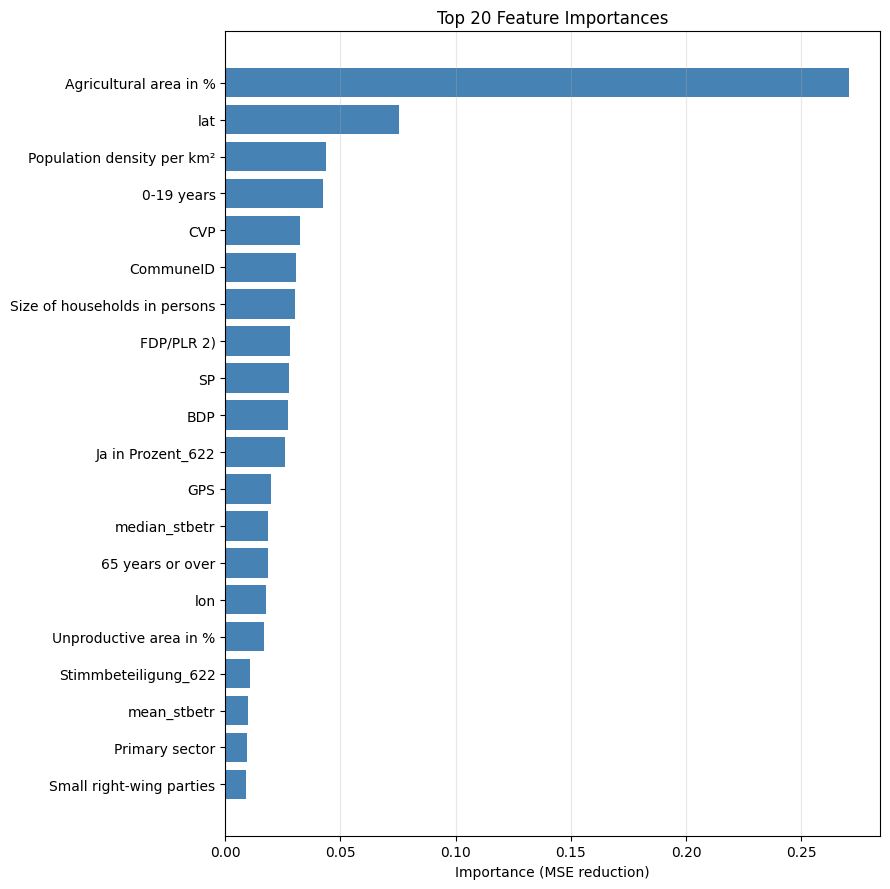

In [19]:

gbr_fitted   = best_model.named_steps['regressor']
importances  = gbr_fitted.feature_importances_

fi_df = pd.DataFrame({'feature': X_train.columns, 'importance': importances}).drop(columns=["CommuneID"])
fi_df = fi_df.sort_values('importance', ascending=False).reset_index(drop=True)

print(fi_df.to_string(index=False))

# Plot top-20 features
top_n = min(20, len(fi_df))
top_fi = fi_df.head(top_n)

fig, ax = plt.subplots(figsize=(9, top_n * 0.4 + 1))
bars = ax.barh(top_fi['feature'][::-1], top_fi['importance'][::-1], color='steelblue')
ax.set_xlabel('Importance (MSE reduction)')
ax.set_title(f'Top {top_n} Feature Importances')
ax.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

Prédiction de `X_test` et production d'un ficher `csv` prêt à la soumission pour la compétition Kaggle

In [12]:
y_predict = grid.predict(X_test)
print(best_cv_rmse)

submission_df = pd.DataFrame({
    'Id': X_test["CommuneID"],
    'Predicted': y_predict
})

submission_df.to_csv("submission_boosting.csv", index=False)
print("Saved submission_boosting.csv for Kaggle")

display(submission_df.head())

5.821296398408563
Saved submission_boosting.csv for Kaggle


,Id,Predicted
0,69,47.813812
1,981,41.562035
2,5432,33.291443
3,387,47.142746
4,2194,35.124355
